# 02 · Preparación: features y ausencia de fuga

**Responsabilidad:** construir las variables del modelo, demostrar que no usan información futura y mostrar por qué algunas "derivan".

Las 9 features son relativas y sin unidades. Todas usan solo `close` y `volume` hasta el día *t*:

| Feature | Fórmula | Idea |
|---|---|---|
| `ret_0` … `ret_4` | rendimiento de *t*, *t−1*, …, *t−4* | rezagos / momentum de corto plazo |
| `ma5_rel`, `ma10_rel`, `ma20_rel` | `close / media_móvil − 1` | posición del precio frente a su tendencia |
| `vol_rel` | `volumen / media_20 − 1` | volumen anormal |

**Por qué relativas:** el precio pasó de unos 240 a unos 500 USD. En niveles, el test de deriva saltaría siempre solo por la tendencia.

**Sustento:** son similares a las features técnicas de [6] p. 5. La elección exacta es propia del equipo (research.md).

> **Nota:** El README menciona "volatilidad de Parkinson, RSI y MACD". **No están implementadas.** Estas 9 son las únicas.

In [1]:
import os, pathlib, warnings
warnings.filterwarnings("ignore")
root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # todas las rutas del proyecto son relativas a la raíz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msft_mlops.config import load_config
from msft_mlops.data import load_raw
from msft_mlops.features import build_dataset

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
# Paleta validada (dataviz): A azul, B naranja, C aqua; baselines y neutros en gris.
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MARKER = {"A": "o", "B": "s", "C": "^"}
GRIS = "#8a8a85"

cfg = load_config()
f = cfg["features"]
FEAT_KW = dict(n_lags=f["n_lags"], ma_windows=tuple(f["ma_windows"]), vol_ma_window=f["vol_ma_window"])
raw = load_raw(cfg)              # falla si el SHA-256 no coincide con config/experiment.toml
ds = build_dataset(raw, **FEAT_KW)
FEATS = [c for c in ds.columns if c != "y"]
print(f"raw: {len(raw)} filas | dataset modelable: {len(ds)} filas, {len(FEATS)} features")

raw: 1254 filas | dataset modelable: 1234 filas, 9 features


## 1. Cómo se ven las features

,mean,std,min,max
ret_0,6.830e-04,0.016,-0.100,0.101
ret_1,6.671e-04,0.016,-0.100,0.101
ret_2,7.376e-04,0.016,-0.077,0.101
ret_3,7.518e-04,0.016,-0.077,0.101
ret_4,7.460e-04,0.016,-0.077,0.101
ma5_rel,1.171e-03,0.017,-0.071,0.066
ma10_rel,2.720e-03,0.025,-0.089,0.110
ma20_rel,5.724e-03,0.036,-0.092,0.136
vol_rel,8.429e-03,0.350,-0.760,3.020


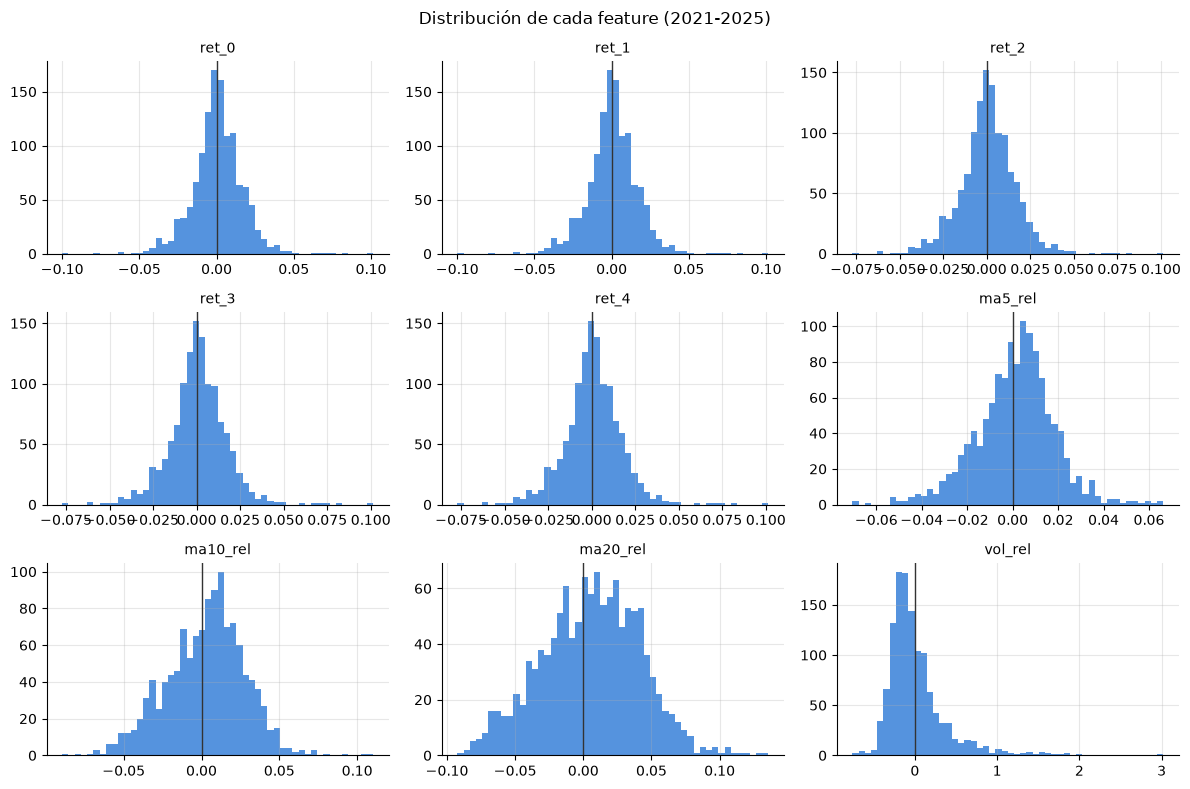

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, c in zip(axes.flat, FEATS):
    ax.hist(ds[c], bins=50, color=COLOR["A"], alpha=0.8); ax.axvline(0, color="#333", lw=1); ax.set_title(c, fontsize=10)
fig.suptitle("Distribución de cada feature (2021-2025)"); plt.tight_layout()
ds[FEATS].describe().T[["mean", "std", "min", "max"]]

**Cómo leerlo:** cada histograma muestra cuántos días toma cada valor la feature; la línea marca el 0.

**Qué concluimos:** Todas están centradas cerca de 0 y en escalas comparables (fracciones del precio o del volumen). Ninguna depende del nivel absoluto del precio, y esa es la condición para que el test de deriva compare periodos distintos de forma justa.

## 2. Prueba de ausencia de fuga (leakage)

Hay **fuga** cuando el modelo usa, sin querer, información que en la realidad todavía no existiría. Por ejemplo, una media móvil "centrada" que incluye días futuros.

**Prueba:** se alteran al azar todos los precios y volúmenes **posteriores** a una fecha *t* y se recalculan las features. Si las features hasta *t* no cambian, no miran el futuro.

OK: en 20 fechas al azar, alterar el futuro no cambia ninguna feature pasada


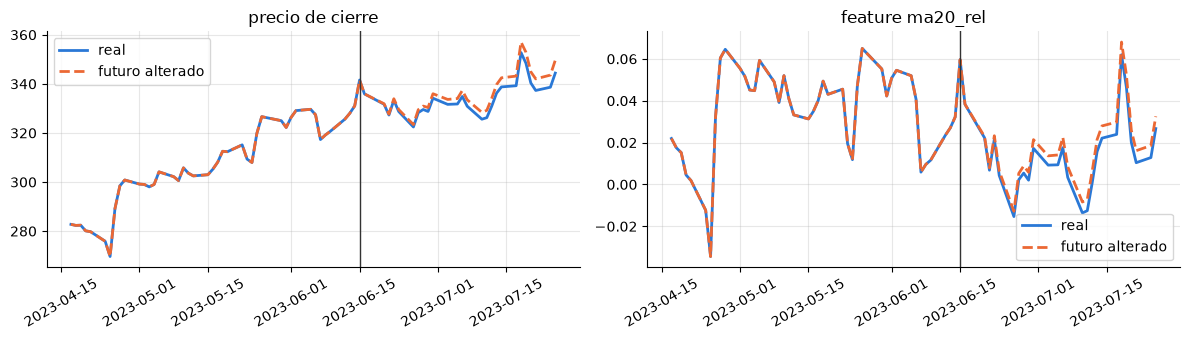

In [3]:
rng = np.random.default_rng(0)
fechas = rng.choice(ds.index[30:-5], size=20, replace=False)
for t in fechas:
    i = raw.index[raw.date == t][0]
    fake = raw.copy()
    fake.loc[i + 1:, ["close", "volume"]] *= rng.uniform(0.5, 1.5, size=(len(fake) - i - 1, 2))
    assert np.allclose(build_dataset(fake, **FEAT_KW).loc[:t, FEATS], ds.loc[:t, FEATS]), f"fuga en {t}"
print(f"OK: en {len(fechas)} fechas al azar, alterar el futuro no cambia ninguna feature pasada")

# Ilustración con una fecha
t = pd.Timestamp("2023-06-15"); i = raw.index[raw.date == t][0]
fake = raw.copy(); fake.loc[i + 1:, "close"] *= np.linspace(1, 1.4, len(fake) - i - 1)
dsf = build_dataset(fake, **FEAT_KW); rango = slice(t - pd.Timedelta(days=60), t + pd.Timedelta(days=40))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
a1.plot(raw.set_index("date").close[rango], color=COLOR["A"], label="real"); a1.plot(fake.set_index("date").close[rango], color=COLOR["B"], ls="--", label="futuro alterado")
a2.plot(ds.ma20_rel[rango], color=COLOR["A"], label="real"); a2.plot(dsf.ma20_rel[rango], color=COLOR["B"], ls="--", label="futuro alterado")
for a, tt in [(a1, "precio de cierre"), (a2, "feature ma20_rel")]:
    a.axvline(t, color="#333", lw=1); a.set_title(tt); a.legend(); a.tick_params(axis="x", rotation=30)
plt.tight_layout()

**Cómo leerlo:** la línea vertical es la fecha *t*. A la derecha se alteró el precio (naranja punteado).

**Qué concluimos:** La feature `ma20_rel` real y la alterada son **idénticas hasta *t*** y solo se separan después. Las features no usan el futuro: el experimento está libre de fuga. Lo mismo se comprueba automáticamente en `tests/unit/test_leakage.py`.

## 3. ¿Hay señal? Correlación de cada feature con `y`

,corr_con_y
ret_2,-0.044
ma20_rel,-0.030
ma10_rel,-0.022
ma5_rel,-0.009
vol_rel,-0.006
ret_3,-0.006
ret_1,-0.003
ret_0,0.013
ret_4,0.014


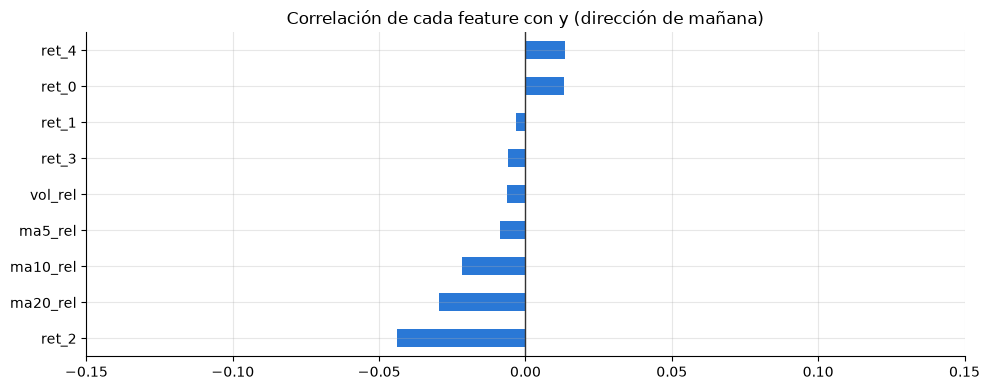

In [4]:
corr = ds[FEATS].corrwith(ds.y).sort_values()
ax = corr.plot.barh(color=COLOR["A"]); ax.axvline(0, color="#333", lw=1); ax.set_xlim(-0.15, 0.15)
ax.set_title("Correlación de cada feature con y (dirección de mañana)"); plt.tight_layout()
corr.to_frame("corr_con_y")

**Cómo leerlo:** cada barra es la correlación entre una feature y la dirección de mañana. 0 significa que no hay relación lineal; ±1 sería una relación perfecta.

**Qué concluimos:** Todas las correlaciones son **muy cercanas a 0**. La dirección del día siguiente es casi impredecible con esta información, como se espera en mercados eficientes ([22]). Por eso se esperan métricas bajas, y el interés está en las **diferencias** entre políticas.

## 4. Distribución por régimen: por qué "deriva" `ma20_rel`

,mediana_ma20_rel,mediana_ret_0
2022-H1,-2.179e-02,-1.274e-03
2022-H2,-5.445e-03,-1.975e-03
2023-H1,3.118e-02,1.116e-03
2023-H2,7.946e-03,1.865e-03
2024-H1,1.456e-02,1.144e-03
2024-H2,7.299e-04,1.133e-03
2025-H1,2.798e-03,1.754e-03
2025-H2,4.815e-03,8.751e-05


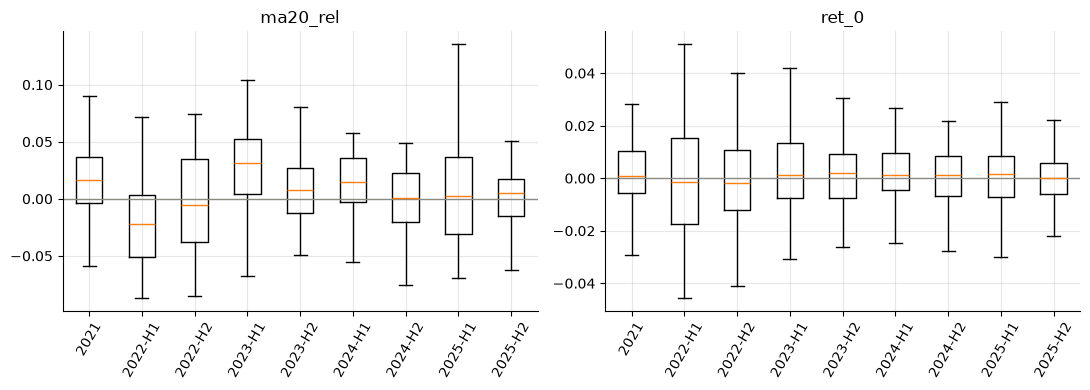

In [5]:
from msft_mlops.windows import split_2021, test_windows
_, _, initial_df = split_2021(ds, cfg["split"])
windows = test_windows(ds, cfg["split"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feat in zip(axes, ["ma20_rel", "ret_0"]):
    data = [initial_df[feat]] + [w.data[feat] for w in windows]
    ax.boxplot(data, tick_labels=["2021"] + [w.window_id for w in windows], showfliers=False)
    ax.axhline(0, color=GRIS, lw=1); ax.set_title(feat); ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
pd.DataFrame({w.window_id: w.data[["ma20_rel", "ret_0"]].median() for w in windows}).T.add_prefix("mediana_")

**Cómo leerlo:** cada caja resume los valores de la feature en un periodo: la línea central es la mediana y la caja contiene el 50 % central de los días.

**Qué concluimos:** `ma20_rel` **se desplaza** con el régimen: está por debajo de 0 en el bajista 2022-H1 y por encima en 2023-H1. `ret_0` en cambio se mantiene parecida. Por eso el test de deriva (notebook 04) salta casi siempre por culpa de las features de tendencia y no de los rendimientos.